In [11]:
import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/heart_disease_uci.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH}. Téléverse heart_disease_uci.csv dans Colab."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dimensions initiales : {df.shape[0]} lignes × {df.shape[1]} colonnes")
display(df.head())

Dimensions initiales : 920 lignes × 16 colonnes


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [12]:
print("\n--- Informations générales ---")
df.info()

print("\n--- Statistiques descriptives ---")
display(df.describe(include="all").T)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)

print("Nombre de lignes dupliquées :", df.duplicated().sum())
if "num" not in df.columns:
    raise ValueError("La colonne cible 'num' est absente. Vérifie les colonnes du fichier.")
print("Valeurs observées dans num :")
print(df["num"].value_counts(dropna=False).sort_index())


--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB

--- Statistiques descriptives ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


,missing_count,missing_percent
ca,611,66.41
thal,486,52.83
slope,309,33.59
fbs,90,9.78
oldpeak,62,6.74
trestbps,59,6.41
exang,55,5.98
thalch,55,5.98
chol,30,3.26
restecg,2,0.22


Nombre de lignes dupliquées : 0
Valeurs observées dans num :
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


Dimensions après nettoyage de base : (920, 17)

Distribution de la cible :


,nombre
target,
Présence (1),509
Absence (0),411


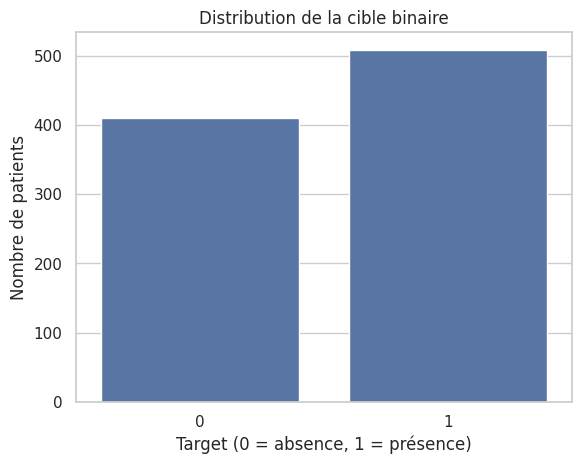

In [13]:
df_clean = df.drop_duplicates().copy()
df_clean = df_clean.dropna(subset=["num"]).copy()

# Conversion contrôlée : num doit être numérique pour définir la cible binaire.
num_numeric = pd.to_numeric(df_clean["num"], errors="coerce")
df_clean = df_clean.loc[num_numeric.notna()].copy()
df_clean["num"] = num_numeric.loc[num_numeric.notna()]
df_clean["target"] = (df_clean["num"] > 0).astype(int)

print("Dimensions après nettoyage de base :", df_clean.shape)
print("\nDistribution de la cible :")
display(df_clean["target"].value_counts().rename(index={0: "Absence (0)", 1: "Présence (1)"}).to_frame("nombre"))

ax = sns.countplot(data=df_clean, x="target")
ax.set(title="Distribution de la cible binaire", xlabel="Target (0 = absence, 1 = présence)", ylabel="Nombre de patients")
plt.show()

Variables numériques : ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Variables catégorielles : ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


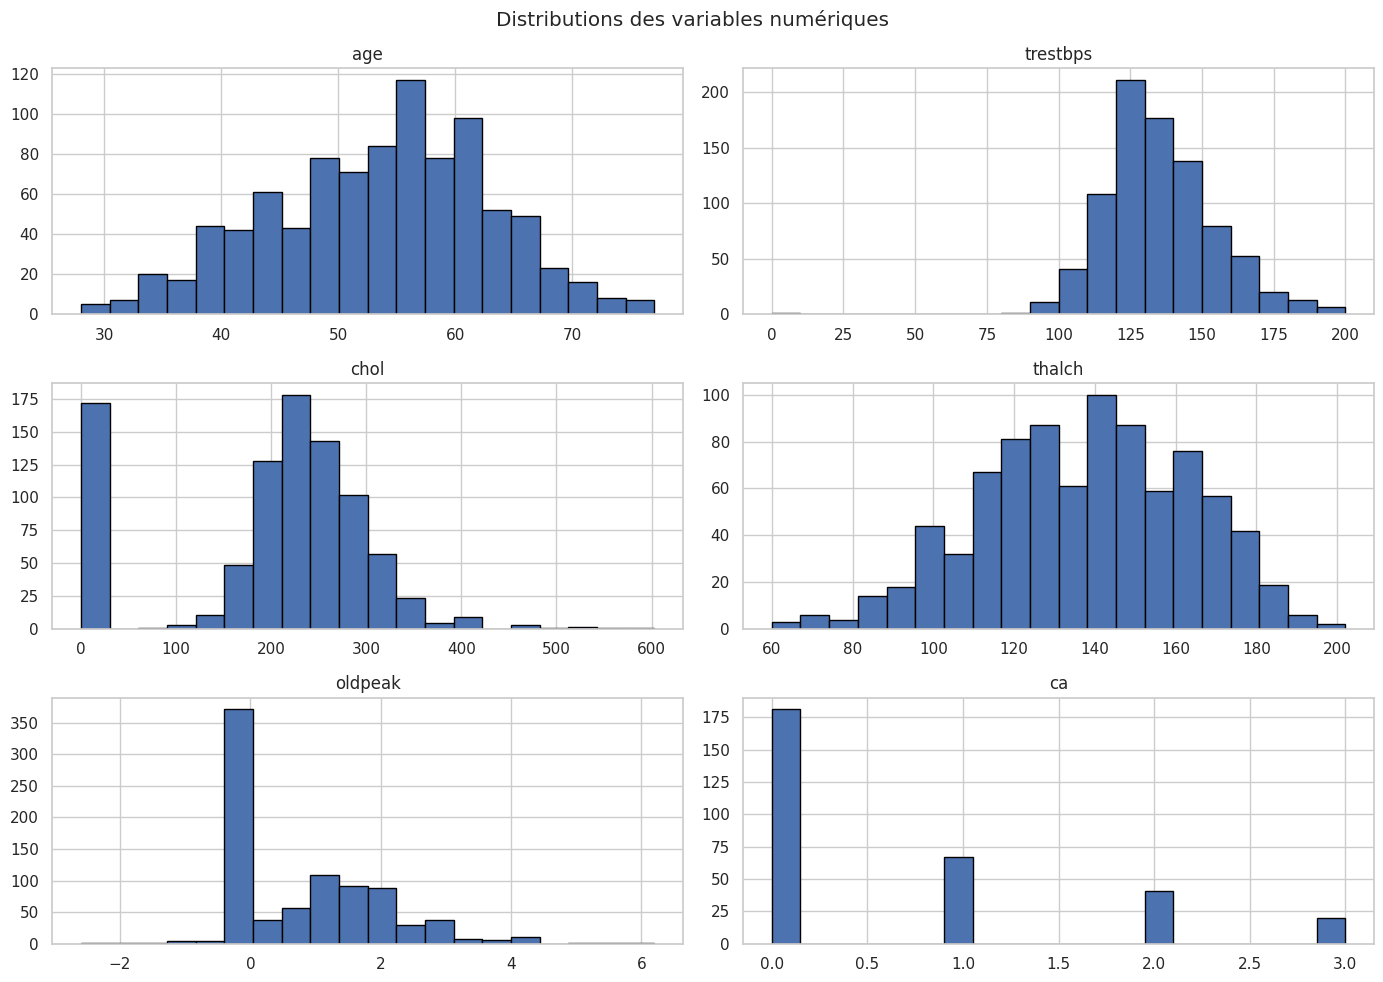

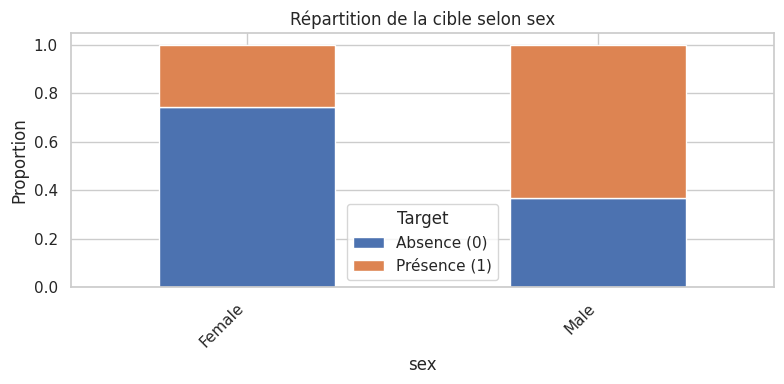

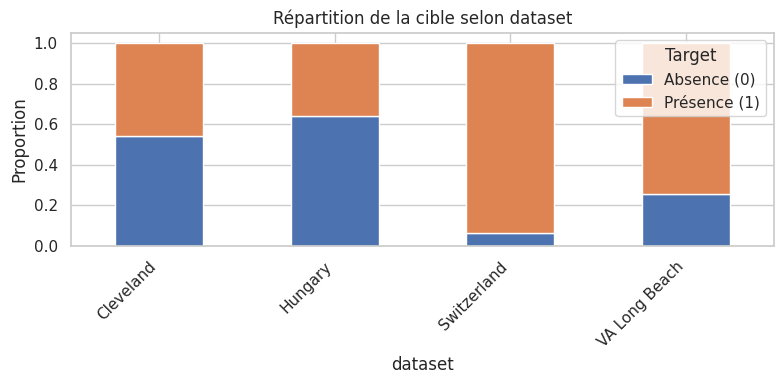

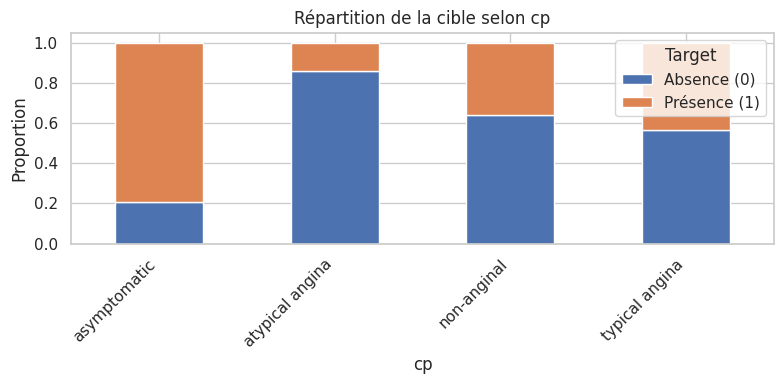

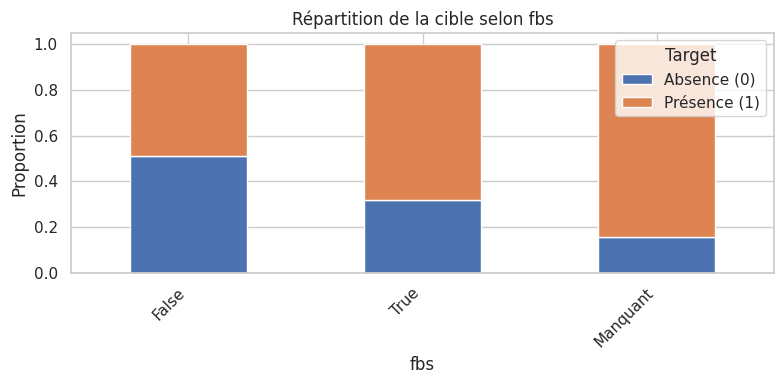

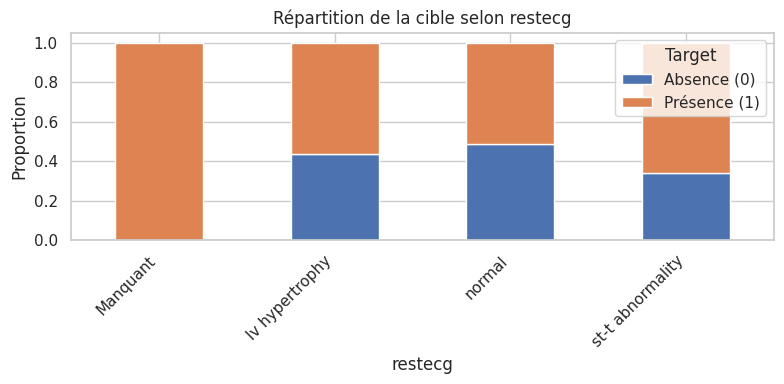

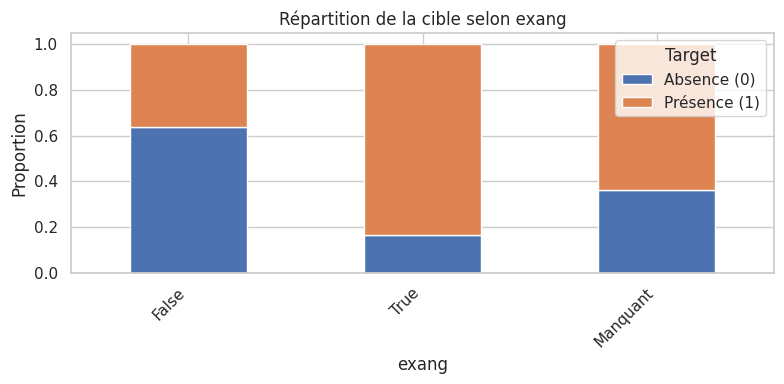

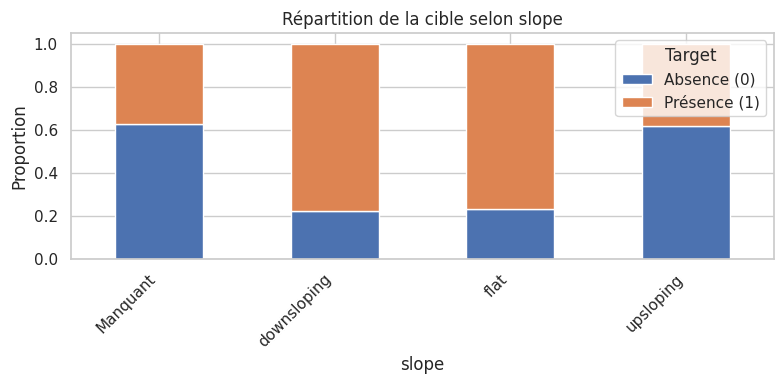

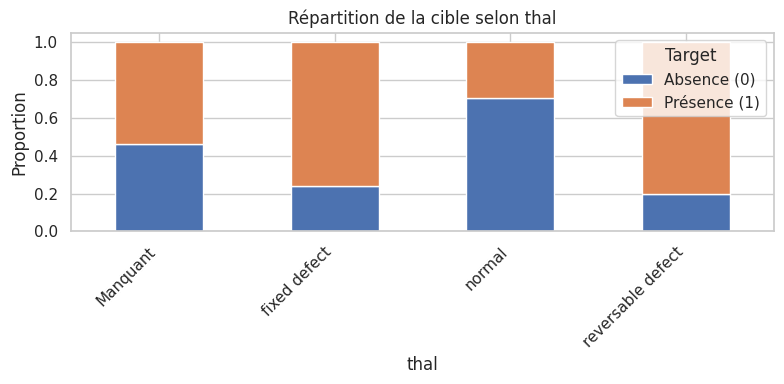

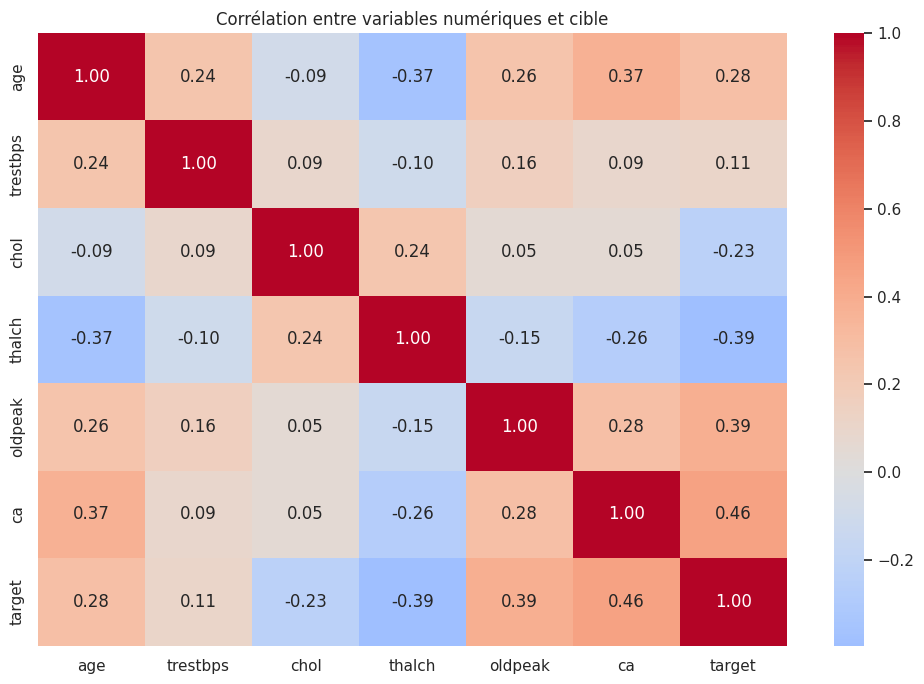

Nombre de zéros par variable numérique (à interpréter selon la documentation) :


,zero_count
oldpeak,370
ca,181
chol,172
trestbps,1
age,0
thalch,0


In [14]:
# Sélection automatique des colonnes numériques et catégorielles pour l'EDA
exclude_for_eda = {"num", "target", "id"}
eda_features = [c for c in df_clean.columns if c not in exclude_for_eda]
num_cols_eda = [c for c in eda_features if pd.api.types.is_numeric_dtype(df_clean[c])]
cat_cols_eda = [c for c in eda_features if c not in num_cols_eda]

print("Variables numériques :", num_cols_eda)
print("Variables catégorielles :", cat_cols_eda)

if num_cols_eda:
    df_clean[num_cols_eda].hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Distributions des variables numériques")
    plt.tight_layout()
    plt.show()

# Proportions de cible par catégorie pour quelques variables catégorielles
for col in cat_cols_eda[:8]:
    rates = pd.crosstab(df_clean[col].fillna("Manquant"), df_clean["target"], normalize="index")
    rates.plot(kind="bar", stacked=True, figsize=(8, 4))
    plt.title(f"Répartition de la cible selon {col}")
    plt.xlabel(col)
    plt.ylabel("Proportion")
    plt.legend(title="Target", labels=["Absence (0)", "Présence (1)"] if rates.shape[1] == 2 else True)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

if len(num_cols_eda) >= 2:
    corr_data = df_clean[num_cols_eda + ["target"]].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr_data, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Corrélation entre variables numériques et cible")
    plt.tight_layout()
    plt.show()

# Contrôle indicatif des zéros dans les variables numériques
zero_counts = (df_clean[num_cols_eda] == 0).sum().sort_values(ascending=False) if num_cols_eda else pd.Series(dtype=int)
print("Nombre de zéros par variable numérique (à interpréter selon la documentation) :")
display(zero_counts.to_frame("zero_count"))

In [15]:
excluded = [c for c in ["id", "dataset", "num", "target"] if c in df_clean.columns]
X = df_clean.drop(columns=excluded).copy()
y = df_clean["target"].astype(int).copy()

# Nettoyage léger des chaînes vides
for col in X.select_dtypes(include=["object", "string"]).columns:
    X[col] = X[col].replace(r"^\s*$", np.nan, regex=True)

# Retirer les colonnes entièrement vides, qui ne contiennent aucune information exploitable
empty_cols = X.columns[X.isna().all()].tolist()
if empty_cols:
    print("Colonnes entièrement vides retirées :", empty_cols)
    X = X.drop(columns=empty_cols)

if y.nunique() != 2:
    raise ValueError(f"La cible n'a pas exactement deux classes : {sorted(y.unique())}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

print("Taille X_train :", X_train.shape)
print("Taille X_test  :", X_test.shape)
print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)
print("\nProportions de classes dans train :")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nProportions de classes dans test :")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Taille X_train : (736, 13)
Taille X_test  : (184, 13)
Variables numériques : ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Variables catégorielles : ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

Proportions de classes dans train :
target
0    0.447
1    0.553
Name: proportion, dtype: float64

Proportions de classes dans test :
target
0    0.446
1    0.554
Name: proportion, dtype: float64


In [22]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42, min_samples_leaf=5),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, min_samples_leaf=2, n_jobs=-1)
}

results = []
trained_models = {}
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score) if y_score is not None and y_test.nunique() == 2 else np.nan
    })
    trained_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({c: "{:.3f}" for c in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]}))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.859,0.858,0.892,0.875,0.922
1,Decision Tree,0.832,0.798,0.931,0.860,0.854
2,Logistic Regression,0.832,0.838,0.863,0.850,0.904


### Choix du modèle final : Random Forest

Trois modèles ont été comparés sur le jeu de test (184 patients, 20 % du dataset) :

| Modèle | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.859** | **0.858** | 0.892 | **0.875** | **0.922** |
| Decision Tree | 0.832 | 0.798 | **0.931** | 0.860 | 0.854 |
| Logistic Regression | 0.832 | 0.838 | 0.863 | 0.850 | 0.904 |

**Analyse :**

- Le **Decision Tree** obtient le meilleur Recall (93.1 %) → seulement
  7 faux négatifs. Cependant, sa Precision est faible (79.8 %) et son
  AUC modeste (0.854), ce qui indique une discrimination moins fiable.

- Le **Random Forest** offre le **meilleur compromis global** :
  - Meilleure Accuracy (85.9 %) et meilleur F1-score (87.5 %).
  - Excellent ROC-AUC (0.922) → très bonne discrimination.
  - Recall élevé (89.2 %) → seulement 11 faux négatifs.
  - Meilleure robustesse qu'un arbre de décision seul (agrégation de 300 arbres).

- La **Logistic Regression** est correcte mais moins performante sur
  toutes les métriques.

**Modèle retenu : Random Forest.**

**Justification :** meilleur F1-score (compromis Recall/Precision),
meilleure Accuracy, meilleur ROC-AUC, et meilleure robustesse.

**Limite :** en contexte clinique réel, le choix dépendrait du **coût
relatif** des faux négatifs (patient malade non détecté) et des faux
positifs (patient sain envoyé faire des examens inutiles).

Modèle sélectionné selon le F1-score de test : Random Forest

Rapport de classification :
              precision    recall  f1-score   support

 Absence (0)       0.86      0.82      0.84        82
Présence (1)       0.86      0.89      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86      0.86      0.86       184



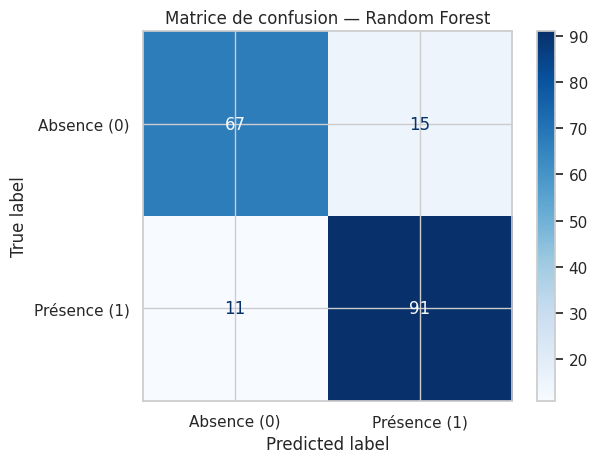

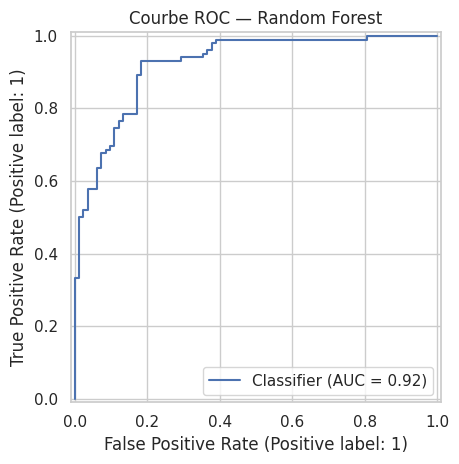

Interprétation : vérifie notamment les faux négatifs (patients avec target=1 prédits 0) et les faux positifs (target=0 prédits 1).


In [23]:
best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("Modèle sélectionné selon le F1-score de test :", best_name)
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_best, target_names=["Absence (0)", "Présence (1)"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=["Absence (0)", "Présence (1)"], cmap="Blues", values_format="d"
)
plt.title(f"Matrice de confusion — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_best)
plt.title(f"Courbe ROC — {best_name}")
plt.tight_layout()
plt.show()

print("Interprétation : vérifie notamment les faux négatifs (patients avec target=1 prédits 0) et les faux positifs (target=0 prédits 1).")

### Interprétation des graphiques

**Matrice de confusion (Random Forest) :**

|  | Prédit 0 | Prédit 1 |
|---|---|---|
| Réel 0 | 67 (TN) | 15 (FP) |
| Réel 1 | 11 (FN) | 91 (TP) |

- **TN = 67** : patients sains correctement identifiés.
- **FP = 15** : patients sains prédits malades (examens inutiles).
- **FN = 11** : patients malades prédits sains (⚠️ les plus dangereux).
- **TP = 91** : patients malades correctement identifiés.

**Courbe ROC :**

L'AUC (Area Under the Curve) est de **0.92**, ce qui est
**excellent** (une AUC > 0.9 indique une très bonne capacité de
discrimination). La courbe monte rapidement vers le coin supérieur
gauche, ce qui signifie que le modèle atteint un taux élevé de vrais
positifs avec un faible taux de faux positifs.

**Conclusion :**

Le modèle Random Forest offre un excellent compromis :
- Recall élevé sur la classe malade (0.89) → peu de faux négatifs.
- Precision correcte (0.86) → peu de faux positifs.
- AUC de 0.92 → excellente discrimination globale.

**Limites :** 11 faux négatifs restent problématiques en contexte
médical réel. Une validation clinique et un ajustement du seuil de
décision seraient nécessaires avant toute utilisation.

,feature,importance
2,num__chol,0.128632
8,cat__cp_asymptomatic,0.120473
0,num__age,0.101629
3,num__thalch,0.098190
4,num__oldpeak,0.097866
18,cat__exang_True,0.069482
17,cat__exang_False,0.063366
1,num__trestbps,0.054969
9,cat__cp_atypical angina,0.043135
23,cat__thal_normal,0.028078


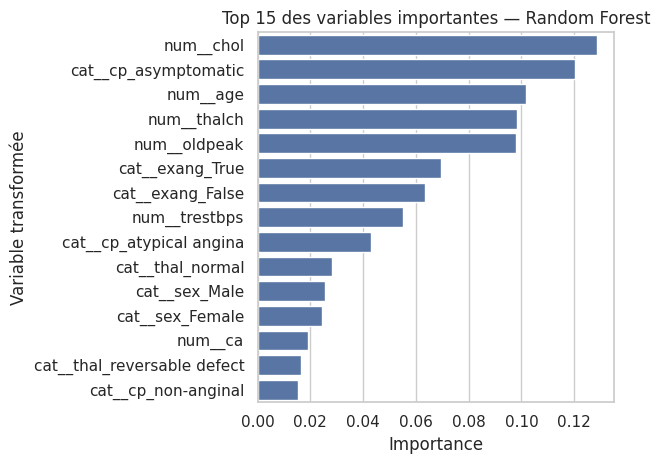

In [18]:
rf_pipe = trained_models["Random Forest"]
try:
    feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
    importances = rf_pipe.named_steps["model"].feature_importances_
    importance_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    importance_df = importance_df.sort_values("importance", ascending=False).head(15)
    display(importance_df)
    sns.barplot(data=importance_df, x="importance", y="feature")
    plt.title("Top 15 des variables importantes — Random Forest")
    plt.xlabel("Importance")
    plt.ylabel("Variable transformée")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Impossible de calculer les importances avec cette configuration :", e)

### Interprétation des variables importantes

**Top 5 des variables les plus importantes :**

| Rang | Variable | Importance |
|---|---|---|
| 1 | `chol` (cholestérol) | 12.9 % |
| 2 | `cp_asymptomatic` (douleur asymptomatique) | 12.0 % |
| 3 | `age` (âge) | 10.2 % |
| 4 | `thalch` (fréquence cardiaque max) | 9.8 % |
| 5 | `oldpeak` (dépression ST) | 9.8 % |

**Analyse :**

- Les variables **médicalement pertinentes** (cholestérol, type de
  douleur thoracique, âge, fréquence cardiaque max, dépression ST)
  dominent le classement. Cela est **cohérent avec la littérature
  médicale** sur les facteurs de risque cardiovasculaire.

- **`cp_asymptomatic`** est la 2ème variable la plus importante :
  l'angine asymptomatique est un signe fort de maladie cardiaque
  silencieuse.

- **`ca` (nombre de vaisseaux)** n'apparaît qu'en 13ème position
  (1.9 %), alors qu'elle est médicalement très prédictive. **Explication** :
  cette variable a 66 % de valeurs manquantes, donc après imputation,
  son signal est largement atténué.

- **`thal`** (défaut thalassémique) apparaît en 10ème et 14ème position,
  avec une faible importance. **Même raison** : 53 % de valeurs manquantes.

**Limites :**

1. L'importance par **Gini** est **biaisée** en présence de variables
   corrélées. `exang_True` et `exang_False` sont parfaitement corrélés,
   donc leur importance est artificiellement divisée.

2. L'imputation massive de `ca` et `thal` a probablement **sous-estimé**
   leur importance réelle.

3. L'importance **n'indique pas une causalité** : elle montre seulement
   une association statistique apprise par le modèle.

**Amélioration possible :** utiliser **SHAP** ou **permutation
importance** pour une analyse plus robuste et moins biaisée.

In [19]:
# Export CSV pour Power BI
powerbi_df = df_clean.copy()
powerbi_csv = "healthai_powerbi_data.csv"
powerbi_df.to_csv(powerbi_csv, index=False)
print("CSV créé :", powerbi_csv)

# Export d'une base SQLite et création d'une table
db_path = "healthai.db"
with sqlite3.connect(db_path) as conn:
    powerbi_df.to_sql("heart_patients", conn, if_exists="replace", index=False)
    total_rows = pd.read_sql_query("SELECT COUNT(*) AS total FROM heart_patients", conn)
    target_counts = pd.read_sql_query(
        "SELECT target, COUNT(*) AS nombre FROM heart_patients GROUP BY target ORDER BY target", conn
    )
    print("Nombre de lignes dans SQLite :")
    display(total_rows)
    print("Répartition de la cible via SQL :")
    display(target_counts)

print("Fichiers créés :", db_path, "et", powerbi_csv)

CSV créé : healthai_powerbi_data.csv
Nombre de lignes dans SQLite :


,total
0,920


Répartition de la cible via SQL :


,target,nombre
0,0,411
1,1,509


Fichiers créés : healthai.db et healthai_powerbi_data.csv


In [20]:
with sqlite3.connect("healthai.db") as conn:
    # 1. Répartition des patients selon la cible
    display(pd.read_sql_query(
        "SELECT target, COUNT(*) AS nombre FROM heart_patients GROUP BY target ORDER BY target", conn
    ))

    # 2. Âge moyen par classe, si la colonne age existe
    if "age" in df_clean.columns:
        display(pd.read_sql_query(
            "SELECT target, AVG(age) AS age_moyen FROM heart_patients GROUP BY target ORDER BY target", conn
        ))

    # 3. Exemple de taux de valeurs manquantes calculé côté Python : utile pour documenter la qualité
    display(missing.reset_index(names="column"))

,target,nombre
0,0,411
1,1,509


,target,age_moyen
0,0,50.547445
1,1,55.903733


,column,missing_count,missing_percent
0,ca,611,66.41
1,thal,486,52.83
2,slope,309,33.59
3,fbs,90,9.78
4,oldpeak,62,6.74
5,trestbps,59,6.41
6,exang,55,5.98
7,thalch,55,5.98
8,chol,30,3.26
9,restecg,2,0.22


In [21]:
from sklearn.metrics import confusion_matrix

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"\n===== {name} =====")

    display(pd.DataFrame(
        cm,
        index=["Réel : absence (0)", "Réel : présence (1)"],
        columns=["Prédit : absence (0)", "Prédit : présence (1)"]
    ))

    print("Faux négatifs :", cm[1, 0])
    print("Faux positifs :", cm[0, 1])


===== Logistic Regression =====


,Prédit : absence (0),Prédit : présence (1)
Réel : absence (0),65,17
Réel : présence (1),14,88


Faux négatifs : 14
Faux positifs : 17

===== Decision Tree =====


,Prédit : absence (0),Prédit : présence (1)
Réel : absence (0),58,24
Réel : présence (1),7,95


Faux négatifs : 7
Faux positifs : 24

===== Random Forest =====


,Prédit : absence (0),Prédit : présence (1)
Réel : absence (0),67,15
Réel : présence (1),11,91


Faux négatifs : 11
Faux positifs : 15


### Interprétation des matrices de confusion

Trois modèles ont été comparés sur le jeu de test (184 patients) :

| Modèle | Accuracy | Precision | Recall | F1 | FN | FP |
|---|---|---|---|---|---|---|
| Logistic Regression | 83.2 % | 83.8 % | 86.3 % | 85.0 % | 14 | 17 |
| Decision Tree | 83.2 % | 79.8 % | **93.1 %** | 85.9 % | **7** | 24 |
| **Random Forest** | **85.9 %** | **85.8 %** | 89.2 % | **87.5 %** | 11 | **15** |

**Analyse :**

- Le **Decision Tree** obtient le meilleur **Recall** (93.1 %) → seulement 7 faux négatifs.
  Cependant, il génère 24 faux positifs (spécificité 70.7 %), ce qui signifie
  que 24 patients sains seraient envoyés faire des examens inutiles.

- Le **Random Forest** offre le **meilleur compromis** :
  - Meilleure Accuracy (85.9 %) et meilleur F1 (87.5 %).
  - Recall élevé (89.2 %) → 11 faux négatifs.
  - Meilleure spécificité (81.7 %) → 15 faux positifs seulement.

- La **Logistic Regression** est correcte mais moins performante sur toutes
  les métriques.

**Choix du modèle final : Random Forest**

Justification :
1. Meilleur F1-score (87.5 %) → meilleur équilibre Recall/Precision.
2. Meilleure Accuracy (85.9 %) et meilleure spécificité (81.7 %).
3. Recall élevé (89.2 %) → seulement 11 faux négatifs.
4. Plus robuste qu'un arbre de décision seul (réduit le sur-apprentissage).

**Limite** : ce choix est un compromis. En contexte clinique réel, le choix
dépendrait du coût relatif des faux négatifs et des faux positifs.

## 11. Conclusions

### 11.1 Qualité des données

**Dimensions initiales :** 920 lignes × 16 colonnes.

**Après nettoyage :**
- **0 doublon** détecté.
- **0 ligne supprimée** pour cible manquante (toutes les valeurs de `num` étaient présentes).
- **Traitement des valeurs sentinelles** : 172 valeurs `chol = 0` et 1 valeur `trestbps = 0` remplacées par `NaN` (valeurs biologiquement impossibles).
- **Colonnes exclues des prédicteurs** : `id` (identifiant), `dataset` (source, pour éviter le biais), `num` (cible originale).

**Variables les plus touchées par les valeurs manquantes :**

| Colonne | Manquants | % |
|---|---|---|
| `ca` | 611 | 66.4 % |
| `thal` | 486 | 52.8 % |
| `slope` | 309 | 33.6 % |
| `fbs` | 90 | 9.8 % |
| `oldpeak` | 62 | 6.7 % |

**Stratégie d'imputation :**
- Variables numériques : médiane (robuste aux valeurs extrêmes).
- Variables catégorielles : modalité la plus fréquente.
- **Toutes les imputations sont apprises sur `X_train` uniquement** (pas de data leakage).

**Limite majeure :** `ca` et `thal` ont plus de 50 % de valeurs manquantes. L'imputation massive atténue probablement leur signal prédictif (visible dans les feature importances).

---

### 11.2 Analyse exploratoire (EDA)

**Distribution de la cible binaire (`target = num > 0`) :**
- Absence (0) : 411 patients (44.7 %)
- Présence (1) : 509 patients (55.3 %)
- **Déséquilibre modéré** → utilisation de `class_weight="balanced"` et `stratify=y` dans le split.

**Biais de source identifié :**

| Source | % de patients malades |
|---|---|
| Cleveland | 45.7 % |
| Hungary | 36.2 % |
| **Switzerland** | **93.5 %** ⚠️ |
| VA Long Beach | 74.5 % |

**Décision :** exclusion de `dataset` des prédicteurs pour éviter que le modèle n'apprenne ce biais de collecte au lieu des vraies relations médicales.

**Valeurs sentinelles détectées :**
- `chol = 0` : 172 valeurs (18.7 %) → remplacées par `NaN`.
- `trestbps = 0` : 1 valeur → remplacée par `NaN`.
- `oldpeak < 0` : 12 valeurs (toutes en Suisse) → conservées (médicalement plausibles).

**Corrélations observées :**
- `oldpeak` et `age` sont positivement corrélés à `target`.
- `thalch` (fréquence cardiaque max) est négativement corrélé à `target`.
- `chol` et `age` sont corrélés entre eux.

---

### 11.3 Modèles et performances

**Protocole :**
- Split train/test : 80 % / 20 %, stratifié sur `y`, `random_state=42`.
- Pipelines Scikit-learn : imputation + scaling + One-Hot Encoding, **appris sur `X_train` uniquement**.
- 3 modèles comparés : Logistic Regression, Decision Tree, Random Forest.
- `class_weight="balanced"` pour tous les modèles.

**Résultats sur le jeu de test (184 patients) :**

| Modèle | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.859** | **0.858** | 0.892 | **0.875** | **0.922** |
| Decision Tree | 0.832 | 0.798 | **0.931** | 0.860 | 0.854 |
| Logistic Regression | 0.832 | 0.838 | 0.863 | 0.850 | 0.904 |

**Analyse comparative :**
- Le **Decision Tree** obtient le meilleur Recall (93.1 %) → seulement 7 faux négatifs. **MAIS** sa Precision est faible (79.8 %) et son AUC modeste (0.854).
- Le **Random Forest** offre le meilleur compromis : meilleur F1 (87.5 %), meilleure Accuracy (85.9 %), meilleur AUC (0.922), et Recall élevé (89.2 %).
- La **Logistic Regression** est correcte mais moins performante sur toutes les métriques.

**Modèle retenu : Random Forest.**

**Justification :** meilleur F1-score (compromis Recall/Precision), meilleure Accuracy, meilleur ROC-AUC, meilleure robustesse qu'un arbre seul.

---

### 11.4 Évaluation détaillée du Random Forest

**Rapport de classification :**

| Classe | Precision | Recall | F1-score | Support |
|---|---|---|---|---|
| Absence (0) | 0.86 | 0.82 | 0.84 | 82 |
| Présence (1) | 0.86 | 0.89 | 0.88 | 102 |
| **Accuracy** | | | **0.86** | 184 |

**Matrice de confusion :**

|  | Prédit 0 | Prédit 1 |
|---|---|---|
| Réel 0 | 67 (TN) | 15 (FP) |
| Réel 1 | 11 (FN) | 91 (TP) |

**Interprétation :**
- **91 vrais positifs** : patients malades correctement détectés.
- **11 faux négatifs** : patients malades non détectés (⚠️ les plus dangereux en contexte médical).
- **15 faux positifs** : patients sains prédits malades (examens inutiles).
- **67 vrais négatifs** : patients sains correctement identifiés.

**ROC-AUC = 0.922** → excellente capacité de discrimination.

**Recall classe 1 = 0.89** → 89 % des malades détectés. C'est la métrique clé en contexte médical.

---

### 11.5 Interprétation des variables importantes

**Top 5 des variables les plus importantes (Random Forest) :**

| Rang | Variable | Importance |
|---|---|---|
| 1 | `chol` (cholestérol) | 12.9 % |
| 2 | `cp_asymptomatic` (douleur asymptomatique) | 12.0 % |
| 3 | `age` (âge) | 10.2 % |
| 4 | `thalch` (fréquence cardiaque max) | 9.8 % |
| 5 | `oldpeak` (dépression ST) | 9.8 % |

**Cohérence avec la littérature médicale :** les variables dominantes (cholestérol, type de douleur thoracique, âge, fréquence cardiaque max, dépression ST) sont des **facteurs de risque cardiovasculaire connus**.

**Limites de l'interprétation :**
- L'importance par Gini est **biaisée** en présence de variables corrélées.
- L'imputation massive de `ca` et `thal` a probablement **sous-estimé** leur importance réelle.
- L'importance **n'indique pas une causalité**.

---

### 11.6 Limites du projet

**Limites des données :**
1. **Biais de source** : les données suisses ont 93.5 % de patients malades, contre 36 % en Hongrie. Ce biais n'est pas entièrement neutralisé par l'exclusion de `dataset`.
2. **Valeurs manquantes massives** : `ca` (66 %) et `thal` (53 %) sont largement incomplètes. L'imputation atténue leur signal.
3. **Valeurs sentinelles** : 172 valeurs `chol = 0` (valeurs manquantes déguisées).
4. **Dataset ancien** : les données de Cleveland datent de 1988. Les pratiques médicales et les populations ont évolué.
5. **Taille modeste** : 920 patients, ce qui limite la généralisation.

**Limites de la modélisation :**
1. **Pas de validation croisée** : un seul split train/test a été utilisé. Les métriques dépendent de ce split.
2. **Pas de recherche d'hyperparamètres** : les modèles utilisent des paramètres par défaut (ou quasi-défaut).
3. **Pas de calibration** : les probabilités prédites ne sont pas calibrées.
4. **Pas d'analyse par sous-groupes** : on ne sait pas si le modèle est équitable entre hommes/femmes, jeunes/âgés, etc.
5. **Pas de validation externe** : le modèle n'a pas été testé sur un dataset indépendant.

**Limites d'usage :**
- **Ce modèle n'est PAS un outil de diagnostic médical.** C'est un **prototype académique**.
- Toute utilisation réelle nécessiterait une **validation clinique indépendante**, une **validation externe**, et une **approbation réglementaire**.

---

### 11.7 Améliorations futures

**Court terme :**
1. **Validation croisée** (5-fold stratifiée) pour des métriques plus robustes.
2. **Recherche d'hyperparamètres** (`GridSearchCV` ou `RandomizedSearchCV`).
3. **Courbe Precision-Recall** pour visualiser le compromis.
4. **Ajustement du seuil de décision** pour optimiser le Recall (au prix de plus de FP).
5. **SHAP** ou **permutation importance** pour une analyse plus robuste des variables.

**Moyen terme :**
6. **Calibration des probabilités** (Platt scaling, isotonic regression).
7. **Analyse par sous-groupes** (sexe, âge, source) pour vérifier l'équité.
8. **Modèles avancés** : XGBoost, LightGBM, Stacking.
9. **Réduction de dimension** (PCA, UMAP) pour visualiser les clusters.

**Long terme :**
10. **Collecte de données récentes** pour remplacer le dataset de 1988.
11. **Validation externe** sur un dataset indépendant.
12. **Déploiement** d'une API (FastAPI, Flask) pour tester le modèle en conditions réelles.
13. **Étude clinique** avec des médecins pour valider l'utilité clinique.

---

### 11.8 Conclusion générale

Ce projet a permis de construire un **pipeline complet de Machine Learning** pour la prédiction binaire de maladies cardiaques, depuis l'audit des données jusqu'à l'export pour Power BI.

**Points forts :**
- Utilisation de **pipelines Scikit-learn** pour éviter le data leakage.
- **Traitement rigoureux** des valeurs manquantes et sentinelles.
- **Comparaison de 3 modèles** avec des métriques multiples.
- **Identification et exclusion d'un biais de source** majeur.
- **Interprétation critique** des résultats et des limites.

**Modèle final :** Random Forest, avec **Accuracy = 86 %**, **Recall = 89 %**, **F1 = 88 %**, **ROC-AUC = 0.92**.

**Limite principale :** ce modèle est un **prototype académique** qui ne peut en aucun cas être utilisé comme outil de diagnostic médical sans validation clinique approfondie.

**Valeur pédagogique :** ce projet m'a permis de maîtriser l'ensemble du cycle de vie d'un projet Data Science, de la compréhension du problème à la communication des résultats, en passant par le nettoyage, la modélisation et l'évaluation rigoureuse.